# Experimento A/B en una landing page: Conversión, gasto y fuentes de tráfico

**Caso de negocio simulado del bootcamp de Data Analytics de TripleTen.** Los datos son ficticios.

**Pregunta de negocio:** ¿qué versión de la página de inicio rinde mejor y qué fuentes de tráfico y tipos de usuario convierten más?

**Datos:** 40,000 usuarios (19,982 en la página A y 20,018 en la B), del 1 al 28 de enero de 2026. Sin valores nulos.

**Herramientas:** Python (pandas, NumPy, SciPy, statsmodels, seaborn, Matplotlib).

**Hallazgos principales**
1. La página B convierte más que la A (15.96% frente a 12.57%, unos 3.4 puntos más; z = −9.68, p < 0.001), y sus usuarios convertidos gastan más (Welch T-Test, p < 0.001).
2. Email es la fuente con mayor tasa de conversión (14.99%), aunque las diferencias entre fuentes son pequeñas. Organic aporta el mayor volumen de conversiones.
3. El tipo de usuario (nuevo o recurrente) no se asocia con la conversión (p = 0.474).

## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [ ]:
# importar librerías
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

In [ ]:
# cargar archivo
df = pd.read_csv('/datasets/landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [ ]:
# mostrar las primeras 5 filas
df.head()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [ ]:
# información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


**Mis hallazgos:**

- - No hay problemas de valores faltantes: Las 40,000 filas tienen 40,000 valores no nulos en todas las columnas. Por lo tanto, no sería necesario imputar ni eliminar registros por valores nulos.

- - Único punto a corregir/revisar: La columna `date` aparece como tipo `object`, aunque sus valores parecen tener formato de fecha. Si efectivamente son fechas, las convertiría y verificaría que no hayan aparecido valores inválidos.

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [ ]:
df['user_id'].nunique()

40000

 **Variable `date`**  
Explorar rango de fechas

In [ ]:
# Resumen estadístico
df["date"].describe()

count          40000
unique            28
top       2026-01-24
freq            1512
Name: date, dtype: object

In [ ]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01
Fecha máxima: 2026-01-28


**Variable `gasto` (numérica)**

In [ ]:
# Resumen estadístico
df["gasto"].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [ ]:
# Resumen estadístico de usuarios que se convirtieron
df[df['converted'] == 1].describe(include='number')

,converted,gasto
count,5706.0,5706.000000
mean,1.0,65.373668
std,0.0,30.896545
min,1.0,12.120000
25%,1.0,42.950000
50%,1.0,59.860000
75%,1.0,80.370000
max,1.0,303.680000


 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [ ]:
# Explorar variables categóricas y cómo se distribuyen
print("\nConteo de categorías:")
print(df['landing'].value_counts(normalize=True))
print(df['region'].value_counts(normalize=True))
print(df['dispositivo'].value_counts(normalize=True))
print(df['traffic_source'].value_counts(normalize=True))
print(df['user_type'].value_counts(normalize=True))



Conteo de categorías:
B    0.50045
A    0.49955
Name: landing, dtype: float64
Norte        0.279150
Centro       0.240325
Sur          0.200975
Occidente    0.159950
Oriente      0.119600
Name: region, dtype: float64
Mobile     0.620725
Desktop    0.379275
Name: dispositivo, dtype: float64
Organic     0.449675
Ads         0.298375
Email       0.153075
Referral    0.098875
Name: traffic_source, dtype: float64
Nuevo         0.650825
Recurrente    0.349175
Name: user_type, dtype: float64


**Mis hallazgos:**
- - Fechas: No se observa ningún error evidente en las fechas. El periodo está dentro de enero de 2026 y no aparecen fechas negativas, imposibles o fuera de rango.

- - Variable `gasto`: No hay valores negativos, por lo que no se observa un error evidente. Sin embargo, hay una distribución muy sesgada: la mayoría de los usuarios no gastó y unos pocos presentan gastos elevados. Esto no necesariamente es un error, pero conviene revisarlo antes del análisis estadístico.

- - Usuarios `converted`: 5,706 usuarios con converted = 1. Su gasto promedio es de aproximadamente 65.37. El gasto mínimo entre los convertidos es 12.12 y el máximo 303.68. Esto parece coherente: los usuarios convertidos presentan gasto positivo.

- - Variables categóricas:
- `landing`: B = 50.045%, A = 49.955%. Distribución prácticamente 50/50, sin anomalías.
- `region`: Norte = 27.9%, Centro = 24.0%, Sur = 20.1%, Occidente = 16.0%, Oriente = 12.0%. Las categorías están bien escritas y no hay categorías extrañas.
- `dispositivo`: Mobile = 62.1%, Desktop = 37.9%. Sin errores aparentes.
- `traffic_source`: Organic = 44.97%, Ads = 29.84%, Email = 15.31%, Referral = 9.89%. Sin errores aparentes en las categorías.
- `user_type`: Nuevo = 65.88%, Recurrente = 34.92%. Las categorías son coherentes y están correctamente escritas.

No se observan errores evidentes de calidad de datos en las tablas mostradas: no hay valores nulos, `user_id` duplicados, categorías mal escritas ni valores negativos en `gasto`.

Lo único que recomendaría investigar, aunque no necesariamente sea un error, es la distribución de `gasto`: el 75% de los registros tiene gasto 0 y existe un máximo de 303.68. Como siguiente paso, convendría revisar outliers de gasto y confirmar que esos valores altos sean reales y no errores de captura.

## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [ ]:
# Gasto por versión
gasto_A = df[(df['landing'] == 'A') & (df['converted'] == 1)]['gasto']
gasto_B = df[(df['landing'] == 'B') & (df['converted'] == 1)]['gasto']


# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)

(2512, 3194)

### Prueba de Levene

**Hipótesis:**
- **Hipótesis nula (H₀):** las varianzas de los dos grupos son iguales.
- **Hipótesis alternativa (H₁):** las varianzas de los dos grupos son diferentes.

In [ ]:
# Aplicar prueba
from scipy.stats import levene
from scipy.stats import ttest_ind

l_stat, p_value_var = levene(gasto_A, gasto_B)

# Visualizar resultados
print(f"Estadístico de Levene: {l_stat}")
print(f"Valor p: {p_value_var}")
alpha = 0.05 # umbral de significancia
if p_value_var < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de varianzas diferentes.")
else:
    print ( "No rechazamos la hipótesis nula: no hay evidencia de varianzas diferentes.")

Estadístico de Levene: 29.17646453202917
Valor p: 6.875301988016449e-08
Rechazamos la hipótesis nula: hay evidencia de varianzas diferentes.


### 📝 Conclusión e interpretación

**Decisión:**  
- - Se rechaza la hipótesis nula de que las varianzas son iguales.

**Interpretación de negocio:**  

- - Los resultados de la prueba de Levene indican que las varianzas del gasto en las páginas A y B son estadísticamente diferentes. Esto significa que la variabilidad del gasto no es la misma en los usuarios de A y B. Es decir, una de las páginas presenta una dispersión de gastos significativamente diferente a la otra. Pero la prueba de Levene no nos dice cuál página tiene mayor gasto promedio ni demuestra que las medias sean diferentes. Solo nos dice que no podemos asumir varianzas iguales. Por eso, este resultado refuerza la decisión de utilizar un Welch T-Test para comparar el gasto promedio.


---


## 📈 Paso 3: Comparar el gasto promedio y la tasa de conversión entre A y B

Se evalua si existen diferencias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### 3.1 Gasto promedio: Welch T-Test

**Hipótesis:**
- **Hipótesis nula (H₀):** el gasto promedio de los usuarios convertidos de A y B es igual.
- **Hipótesis alternativa (H₁):** el gasto promedio de A y B es diferente.

In [ ]:
# Número de usuarios convertidos por página
conversiones = df.groupby('landing')['converted'].sum()

# Total de usuarios por página
totales = df.groupby('landing')['converted'].count()

print("Usuarios convertidos por página:\n", conversiones)
print("\nTotal de usuarios por página:\n", totales)


Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: converted, dtype: int64


In [ ]:
# Aplicar prueba
t_stat, p_value = ttest_ind(
    gasto_A,
    gasto_B,
    equal_var=False
)


# Visualizar resultados
print(f"Estadístico t: {t_stat}")
print(f"Valor p: {p_value}")

Estadístico t: -9.48101092267275
Valor p: 3.627602231521493e-21


### 📝 Conclusión e interpretación

**Decisión:**  
- Sí se rechaza la hipótesis nula, porque el p-value de la Welch T-Test es < 0.05. Por lo tanto, existe evidencia estadísticamente significativa de que el gasto promedio de los usuarios convertidos es diferente entre A y B.

**Interpretación de negocio:**  
Explica qué indica el resultado sobre la tasa de conversión entre la página A y la página B.
- El Welch T-Test compara el gasto, no la tasa de conversión. Para analizar la tasa de conversión debemos usar los números de usuarios. Según la información que tenemos hasta ahora, la página B tiene una tasa de conversión mayor (aproximadamente 1.27 veces lo que convierte A, o alrededor de 26.9% más en términos relativos). La tasa de conversión se evalúa en la sección 3.2.

### 3.2 Tasa de conversión: prueba z de proporciones

**Hipótesis:**
- **H₀:** la tasa de conversión de la página A y la de la B son iguales.
- **H₁:** la tasa de conversión de A y B es diferente.

In [1]:
from statsmodels.stats.proportion import proportions_ztest

conversiones = [2512, 3194]   # usuarios convertidos: A, B
usuarios = [19982, 20018]     # usuarios totales: A, B

z_stat, p_value = proportions_ztest(conversiones, usuarios)
tasa_A, tasa_B = conversiones[0] / usuarios[0], conversiones[1] / usuarios[1]

print(f"Tasa A: {tasa_A:.2%} | Tasa B: {tasa_B:.2%}")
print(f"Diferencia: {(tasa_B - tasa_A) * 100:.2f} puntos porcentuales")
print(f"Estadístico z: {z_stat:.2f}")
print(f"Valor p: {p_value:.2e}")

Tasa A: 12.57% | Tasa B: 15.96%
Diferencia: 3.38 puntos porcentuales
Estadístico z: -9.68
Valor p: 3.76e-22


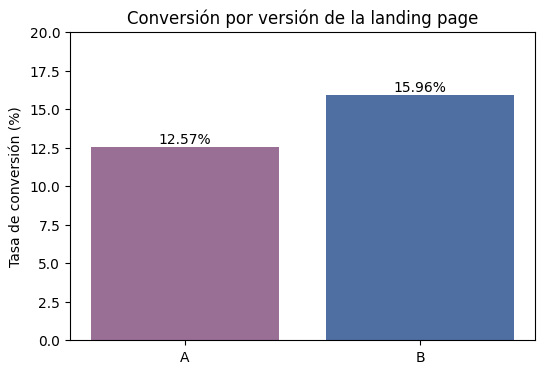

In [2]:
import matplotlib.pyplot as plt

paginas = ['A', 'B']
tasas = [2512 / 19982 * 100, 3194 / 20018 * 100]

fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(paginas, tasas, color=['#9a6f96', '#4f6fa3'])
ax.bar_label(barras, fmt='%.2f%%')
ax.set_ylabel('Tasa de conversión (%)')
ax.set_title('Conversión por versión de la landing page')
ax.set_ylim(0, 20)
plt.show()

### 📝 Conclusión e interpretación
**Decisión:** se rechaza H₀ (p < 0.05).

**Interpretación de negocio:** la página B convierte significativamente más que la A (15.96% frente a 12.57%, unos 3.4 puntos porcentuales más; intervalo de confianza del 95% aproximado: 2.7 a 4.1 puntos).

## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba Chi-cuadrado

**Hipótesis:**
- **Hipótesis nula (H₀):** La fuente de tráfico y la conversión son independientes.
- **Hipótesis alternativa (H₁):** La fuente de tráfico y la conversión no son independientes.

In [ ]:
from scipy.stats import chi2_contingency

In [ ]:
# Aplicar prueba
tabla = pd.crosstab(df['traffic_source'], df['converted'])
print(tabla)

chi2, p_value, dof, expected = chi2_contingency(tabla)

print("Tabla de contingencia:")
print(tabla)

print("\nChi-cuadrado:", chi2)
print("p-value:", p_value)

tasa_conversion = df.groupby('traffic_source')['converted'].mean() * 100

print("Tasa de conversión:")
print(tasa_conversion)


converted           0     1
traffic_source             
Ads             10176  1759
Email            5205   918
Organic         15507  2480
Referral         3406   549
Tabla de contingencia:
converted           0     1
traffic_source             
Ads             10176  1759
Email            5205   918
Organic         15507  2480
Referral         3406   549

Chi-cuadrado: 8.662108841397938
p-value: 0.0341375947833914
Tasa de conversión:
traffic_source
Ads         14.738165
Email       14.992651
Organic     13.787736
Referral    13.881163
Name: converted, dtype: float64


In [ ]:
alpha = 0.05

if p_value < alpha:
    print("Rechazamos H0: existe una relación significativa entre la fuente de tráfico y la conversión.")
else:
    print("No rechazamos H0: no hay evidencia suficiente de una relación entre la fuente de tráfico y la conversión.")

Rechazamos H0: existe una relación significativa entre la fuente de tráfico y la conversión.


### 📝 Conclusión e interpretación

**Decisión:**

- Sí, se rechaza la hipótesis nula de la prueba Chi-cuadrado, porque hay evidencia estadísticamente significativa de que la fuente de tráfico está relacionada con la conversión.

**Interpretación de negocio:**  
Explica qué indican los resultados considerando tanto las cantidades absolutas como las tasas de conversión.

- La prueba Chi-cuadrado indica que las diferencias observadas entre las fuentes de tráfico no parecen deberse únicamente al azar.
- Desde el punto de vista del negocio:
`Organic` es importante por su gran volumen y genera el mayor número absoluto de clientes.
`Email` tiene la mejor tasa de conversión, por lo que parece ser una fuente particularmente eficiente para convertir usuarios.
`Ads` también genera un volumen importante y tiene una tasa de conversión cercana a `Email`.
`Referral` tiene el menor volumen y una tasa ligeramente inferior.
Sin embargo, la prueba Chi-cuadrado por sí sola no determina qué fuente es significativamente mejor que las demás; para saber qué diferencias específicas entre fuentes son significativas habría que realizar comparaciones posteriores de proporciones.


## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba Chi-cuadrado de independencia

**Hipótesis:**
- **Hipótesis nula (H₀):** El tipo de usuario y la conversión son independientes.
- **Hipótesis alternativa (H₁):** El tipo de usuario y la conversión no son independientes.

In [ ]:
tabla = pd.crosstab(df['user_type'], df['converted'])

print(tabla)

converted       0     1
user_type              
Nuevo       22295  3738
Recurrente  11999  1968


In [ ]:
# Aplicar prueba
chi2_stat, p_value, dof, expected = chi2_contingency(tabla)

print(f"Estadístico chi-cuadrado: {chi2_stat:.3f}")
print(f"Valor P: {p_value:.3f}")
print(f"Grados de libertad: {dof}")
print(f"\nfrecuencias esperadas:")
print(expected)

alpha = 0.05

if p_value < alpha:
    print("Rechazamos H0: existe una relación entre el tipo de usuario y la conversión.")
else:
    print("No rechazamos H0: no hay evidencia de una relación entre el tipo de usuario y la conversión.")


Estadístico chi-cuadrado: 0.513
Valor P: 0.474
Grados de libertad: 1

frecuencias esperadas:
[[22319.39255  3713.60745]
 [11974.60745  1992.39255]]
No rechazamos H0: no hay evidencia de una relación entre el tipo de usuario y la conversión.


In [ ]:
tasas_conversion = df.groupby('user_type')['converted'].mean() * 100

print("Tasas de conversión:")
print(tasas_conversion)

Tasas de conversión:
user_type
Nuevo         14.358699
Recurrente    14.090356
Name: converted, dtype: float64


In [ ]:
print("Usuarios convertidos:")
print(df[df['converted'] == 1]['user_type'].value_counts())

Usuarios convertidos:
Nuevo         3738
Recurrente    1968
Name: user_type, dtype: int64


### 📝 Conclusión e interpretación

**Decisión:**  
- No rechazamos la hipótesis nula, porque no tenemos evidencia estadísticamente significativa para afirmar que el tipo de usuario esté relacionado con la conversión.

**Interpretación de negocio:**  
Explica qué indica el resultado.
- No se encontró evidencia estadísticamente significativa de una relación entre el tipo de usuario y la conversión. Aunque los usuarios nuevos presentan una tasa de conversión ligeramente superior a los recurrentes (14.36% vs. 14.10%), la diferencia es pequeña y no puede considerarse significativa. Por lo tanto, con estos datos, el tipo de usuario no parece ser un factor relevante para explicar la conversión.

## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.



### Relación entre la fuente de tráfico y la conversión

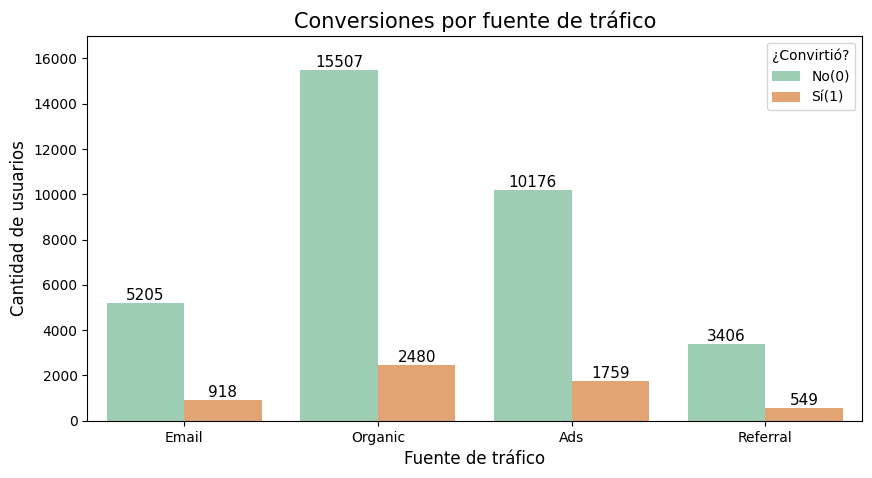

In [ ]:
plt.figure(figsize=(10,5))
ax = sns.countplot(data=df, x='traffic_source', hue='converted', palette = ["#95D5B2", "#F4A261"])

for bar in ax.patches:
    height = bar.get_height()
    ax.text(x=bar.get_x()+bar.get_width() /2,
        y=height,
        s=height,
        ha='center',
        va='bottom',
        fontsize=11)

plt.title('Conversiones por fuente de tráfico', fontsize=15)
plt.xlabel ('Fuente de tráfico', fontsize=12)
plt.ylabel ('Cantidad de usuarios', fontsize=12)
plt.ylim(0,17000)
plt.legend(title='¿Convirtió?', labels=['No(0)', 'Sí(1)'])
plt.show()


**Mis hallazgos:**
- En volumen absoluto, en esta gráfica domina la fuente `Organic`, pues es la fuente que genera más usuarios, y por lo tanto también la que genera más conversiones. Sin embargo, esto no significa que `Organic` sea la fuente más efectiva, porque también tiene muchos más usuarios que las demás.

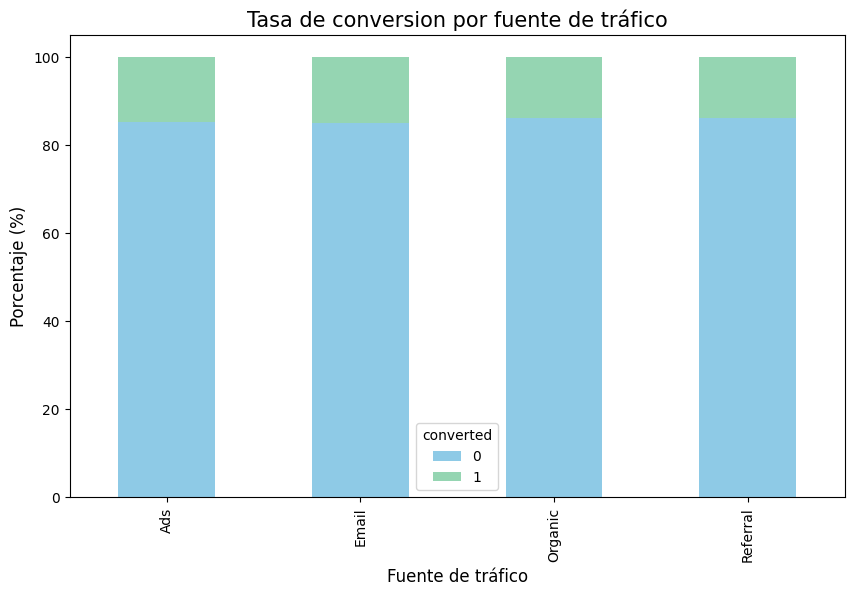

In [ ]:
tabla = pd.crosstab(df['traffic_source'], df['converted'], normalize='index') * 100

tabla.plot(kind='bar', stacked=True, figsize=(10, 6), color=["#8ecae6", "#95d5b2"])

plt.title("Tasa de conversion por fuente de tráfico", fontsize=15)
plt.ylabel("Porcentaje (%)", fontsize=12)
plt.xlabel("Fuente de tráfico", fontsize=12)
plt.show()

**Mis hallazgos:**
- En esta segunda gráfica, donde se muestra la efectividad relativa, la fuente `Email` destaca por tener la mayor tasa de conversión, aunque genera menos conversiones en términos absolutos debido a que tiene menos usuarios.
  
- `Organic` es el principal generador de conversiones en términos absolutos debido a su alto volumen de usuarios, mientras que `Email` presenta la mayor tasa de conversión. Esto indica que la fuente de tráfico influye significativamente en la conversión, aunque las diferencias en efectividad relativa entre fuentes son moderadas. Por ello, `Organic` puede ser clave para generar volumen, mientras que `Email` destaca por su eficiencia para convertir. Sin embargo, no podemos decir todavía que `Email` sea la fuente "más rentable", porque para eso necesitaríamos incorporar el gasto/valor económico generado por cada fuente, no solamente la conversión.

### Relación entre el tipo de usuario y la conversión

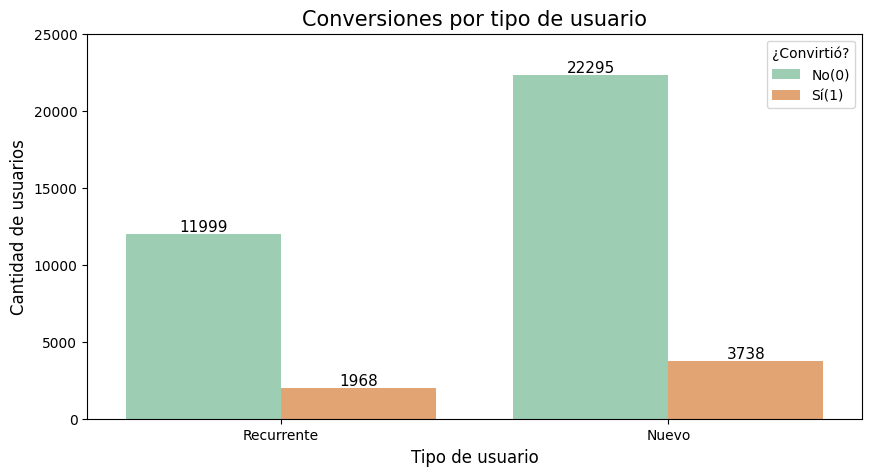

In [ ]:
plt.figure(figsize=(10,5))
ax = sns.countplot(data=df, x='user_type', hue='converted', palette = ["#95D5B2", "#F4A261"])

for bar in ax.patches:
    height = bar.get_height()
    ax.text(x=bar.get_x()+bar.get_width() /2,
        y=height,
        s=height,
        ha='center',
        va='bottom',
        fontsize=11)

plt.title('Conversiones por tipo de usuario', fontsize=15)
plt.xlabel ('Tipo de usuario', fontsize=12)
plt.ylabel ('Cantidad de usuarios', fontsize=12)
plt.ylim(0,25000)
plt.legend(title='¿Convirtió?', labels=['No(0)', 'Sí(1)'])
plt.show()

**Mis hallazgos:**
- En volumen absoluto, los `usuarios nuevos` dominan y es lógico que tengan más conversiones absolutas porque representan aproximadamente el doble de usuarios.

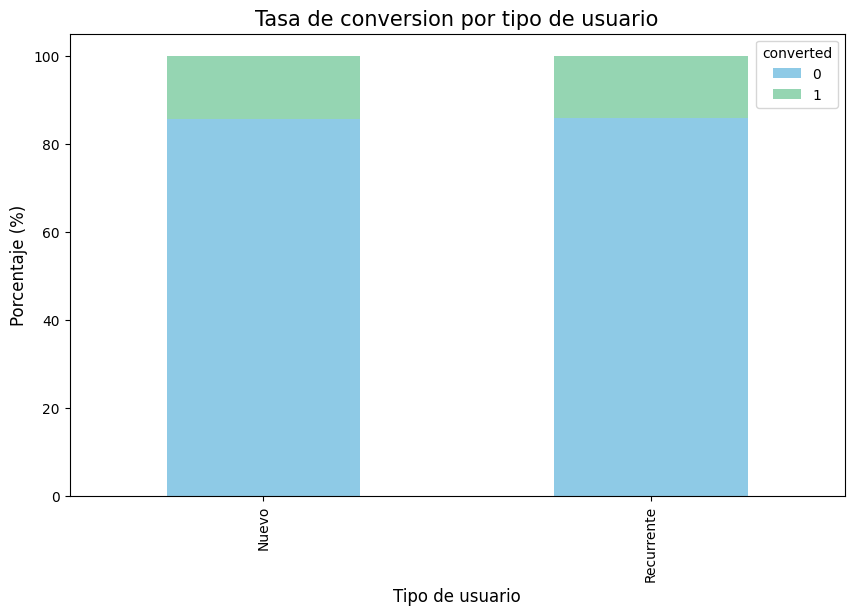

In [ ]:
tabla = pd.crosstab(df['user_type'], df['converted'], normalize='index') * 100

tabla.plot(kind='bar', stacked=True, figsize=(10, 6), color=["#8ecae6", "#95d5b2"])

plt.title("Tasa de conversion por tipo de usuario", fontsize=15)
plt.ylabel("Porcentaje (%)", fontsize=12)
plt.xlabel("Tipo de usuario", fontsize=12)
plt.show()

**Mis hallazgos:**
- En tasa de conversión, prácticamente no hay diferencia. La segunda gráfica muestra que las proporciones de conversión son muy similares. Por tanto, no tenemos evidencia estadística suficiente para afirmar que el tipo de usuario esté relacionado con la conversión.
- Los usuarios `nuevos` generan un mayor número absoluto de conversiones debido a que representan un mayor volumen de usuarios. Sin embargo, las tasas de conversión entre usuarios `nuevos` y `recurrentes` son muy similares y la prueba Chi-cuadrado no encontró una relación estadísticamente significativa entre el tipo de usuario y la conversión (p = 0.474). Por lo tanto, el tipo de usuario no parece ser un factor relevante para explicar la probabilidad de conversión.
- En cambio, la variable `traffic_source` sí mostró una relación significativa con conversión, mientras que `user_type` no. Por ahora, la fuente de tráfico parece ser una variable más útil para explicar diferencias en conversión que el hecho de que el usuario sea nuevo o recurrente.

## 🧩 Paso 7. Insight Ejecutivo para Stakeholders

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**  
- ¿Qué página genera mayor conversión y gasto promedio?  
- ¿Qué canales de tráfico son más efectivos para generar conversiones?  
- ¿Existen diferencias significativas según el tipo de usuario?  
- ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?


---

### 🌟 Insight Ejecutivo basado en el Experimento A/B

#### 🔍 **Comparación de página (A vs B)**  

**Gasto promedio por usuario que convirtió:**
- El Welch T-Test mostró una diferencia estadísticamente significativa en el gasto promedio entre los usuarios convertidos de A y B.
- El estadístico t es negativo al comparar A contra B, lo que indica que, en este análisis, el gasto promedio de B es mayor que el de A. Además, la prueba de Levene mostró que las varianzas son diferentes, por lo que fue adecuado utilizar Welch T-Test.
- **Interpretación:**
La página B genera mayor valor económico por usuario convertido que la página A, y la diferencia observada es estadísticamente significativa. Esto constituye evidencia a favor de B como experiencia de mayor valor para el negocio.

**Tasa de conversión:**
- La página A convirtió 2,512 de 19,982 usuarios, alcanzando una tasa de conversión de aproximadamente 12.57%.
- La página B convirtió 3,194 de 20,018 usuarios, alcanzando una tasa de aproximadamente 15.96%. Esto representa una mejora de alrededor de 3.4 puntos porcentuales y aproximadamente 27% más conversiones en términos relativos frente a A.
- **Interpretación:**
La página B presenta un desempeño claramente superior en conversión. En conjunto con el mayor gasto promedio observado, B se perfila como la alternativa con mayor potencial de generación de valor para el negocio.

---

#### 📊 **Segmentación por fuente de tráfico**
- La prueba Chi-cuadrado encontró una relación estadísticamente significativa entre la `fuente de tráfico` y la `conversión`. En volumen absoluto, `Organic` genera la mayor cantidad de conversiones (2,480) debido a que también concentra el mayor número de usuarios. Sin embargo, en efectividad relativa, `Email` presenta la mayor tasa de conversión (~14.99%), seguido de `Ads` (~14.74%), `Referral` (~13.88%) y `Organic` (~13.79%).
- **Interpretación:**
La `fuente de tráfico` sí parece influir en la conversión. `Organic` es clave por su capacidad de generar volumen, mientras que `Email` destaca por su eficiencia para convertir. Por ello, las decisiones de marketing deberían considerar tanto el volumen generado como la tasa de conversión, y no únicamente el número absoluto de clientes. Las diferencias entre fuentes son pequeñas (de 13.8% a 15.0%), y la prueba indica que existe una asociación global, no que una fuente en particular sea significativamente mejor que otra.

 ---

#### 📊 **Segmentación por tipo de usuario**
- La prueba Chi-cuadrado no encontró una relación estadísticamente significativa entre el `tipo de usuario` y la `conversión`. Aunque los `usuarios nuevos` generan más conversiones absolutas (3,738 vs. 1,968), esto se debe principalmente a que existe un mayor número de usuarios nuevos. Las tasas de conversión son muy similares entre ambos grupos.
- **Interpretación:**
El hecho de que un usuario sea `nuevo` o `recurrente` no parece ser un factor relevante para explicar la conversión. Por lo tanto, no hay evidencia suficiente para justificar estrategias diferenciadas de conversión únicamente con base en esta variable.

---

Las visualizaciones usadas respaldan los resultados estadísticos de pasos anteriores.

---

#### 💡 **Recomendaciones de negocio:**
- Priorizar la `página B` como versión de referencia, ya que presenta una tasa de conversión superior y un gasto promedio significativamente mayor entre los usuarios que convierten. Se recomienda mantenerla como la versión ganadora y continuar monitoreando su desempeño.
- Optimizar la estrategia de adquisición por `fuente de tráfico`: mantener y fortalecer `Organic` por su capacidad de generar volumen y explorar oportunidades para escalar `Email` por su mayor tasa de conversión. Al mismo tiempo, conviene evaluar el costo de adquisición de cada fuente para determinar cuál genera el mejor retorno económico.